In [1]:
import torch
import torch.nn as nn
import numpy
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

In [3]:
diabetes = load_diabetes()

X = diabetes.data
Y = diabetes.target

print(f"Features_shape: {X.shape}")
print(f"Target_shape: {Y.shape}")
print(f"Feature_names: {diabetes.feature_names}")

Features_shape: (442, 10)
Target_shape: (442,)
Feature_names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [10]:
X = torch.tensor(X , dtype = torch.float32)
Y = torch.tensor(Y , dtype = torch.float32)

Y = Y.unsqueeze(1)

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("X dtype:", X.dtype)
print("Y dtype:", Y.dtype)

X shape: torch.Size([442, 10])
Y shape: torch.Size([442, 1])
X dtype: torch.float32
Y dtype: torch.float32


C:\Users\HP\AppData\Local\Temp\ipykernel_11456\2298124191.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X = torch.tensor(X , dtype = torch.float32)
C:\Users\HP\AppData\Local\Temp\ipykernel_11456\2298124191.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Y = torch.tensor(Y , dtype = torch.float32)


In [12]:
X_train, X_test, Y_train , Y_test = train_test_split(X , Y , train_size = 0.8 , random_state = 42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Y_train:", Y_train.shape)
print("Y_test:", Y_test.shape)

X_train: torch.Size([353, 10])
X_test: torch.Size([89, 10])
Y_train: torch.Size([353, 1])
Y_test: torch.Size([89, 1])


In [19]:
class DiabetesModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(
            in_features = 10,
            out_features = 1
        )
    def forward(self,x):
        return self.linear(x)            

In [20]:
torch.manual_seed(42)
model = DiabetesModel()
print(model)

DiabetesModel(
  (linear): Linear(in_features=10, out_features=1, bias=True)
)


In [21]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(params = model.parameters() , lr = 0.1)

print("Loss function:", loss_fn)
print("Optimiser:", optimizer)

Loss function: MSELoss()
Optimiser: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.1
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


In [22]:
torch.manual_seed(42)

epochs = 300
train_loss = []

for epoch in range(epochs):
    model.train()

    Y_pred = model(X_train)

    loss = loss_fn(Y_pred , Y_train)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    train_loss.append(loss.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )


Epoch [50/300], Loss: 5707.0366
Epoch [100/300], Loss: 5389.9795
Epoch [150/300], Loss: 5118.1851
Epoch [200/300], Loss: 4884.5420
Epoch [250/300], Loss: 4683.0908
Epoch [300/300], Loss: 4508.8408


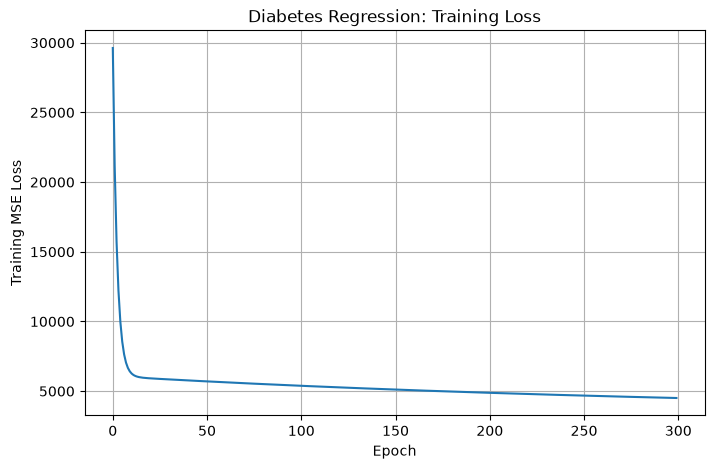

In [23]:
plt.figure(figsize = (8,5))

plt.plot(train_loss)
plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")
plt.title("Diabetes Regression: Training Loss")
plt.grid(True)

plt.show()

In [24]:
model.eval()

with torch.no_grad():
    Y_test_pred = model(X_test)
    test_loss = loss_fn(Y_test_pred , Y_test)

print(f"Test MSE: {test_loss.item():.4f}")

Test MSE: 3922.6279


In [26]:
with torch.no_grad():
    mae = torch.mean(torch.abs(Y_test_pred - Y_test))

print(f"test MAE: {mae.item():.4f}")

test MAE: 53.9544


In [28]:
mae_sklearn = mean_absolute_error(
    Y_test.numpy().ravel(),
    Y_test_pred.numpy().ravel()
)

print(f"MAE using sklearn: {mae_sklearn:.2f}")

MAE using sklearn: 53.95


In [29]:
with torch.no_grad():
    predictions = model(X_test)
for i in range(10):
    print(f"Actual: {Y_test[i].item():.2f} | Predicted: {predictions[i].item():.2f}")

Actual: 219.00 | Predicted: 162.71
Actual: 70.00 | Predicted: 154.60
Actual: 202.00 | Predicted: 160.48
Actual: 230.00 | Predicted: 200.56
Actual: 111.00 | Predicted: 154.63
Actual: 84.00 | Predicted: 146.57
Actual: 242.00 | Predicted: 183.95
Actual: 272.00 | Predicted: 177.84
Actual: 94.00 | Predicted: 136.53
Actual: 96.00 | Predicted: 148.32


In [30]:
model_path = "diabetes_regression_model.pth"
torch.save(model.state_dict() , model_path)
print("Model loaded successfully!")

Model loaded successfully!


In [31]:
loaded_model = DiabetesModel()

state_dict = torch.load(
    model_path,
    map_location = "cpu",
    weights_only = True
)

loaded_model.load_state_dict(state_dict)

loaded_model.eval()
print("model loaded successfulley")

model loaded successfulley


In [32]:
with torch.no_grad():
    loaded_predictions = loaded_model(X_test)

print("First 5 predictions:")
print(loaded_predictions[:5])

# Confirm predictions match the original model
with torch.no_grad():
    original_predictions = model(X_test)

print(
    "Predictions match:",
    torch.allclose(original_predictions, loaded_predictions)
)

First 5 predictions:
tensor([[162.7066],
        [154.5983],
        [160.4806],
        [200.5636],
        [154.6320]])
Predictions match: True


In [34]:
single_patient = X_test[0].unsqueeze(0)

with torch.no_grad():
    prediction = loaded_model(single_patient)

print("Predicted disease progression:", prediction.item())
print("Actual disease progression:", Y_test[0].item())

Predicted disease progression: 162.70655822753906
Actual disease progression: 219.0
